# Privacy-Preserving Training of a PIN-Code Digit Recogniser

In [1]:
%pip -q install opacus

In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from opacus import PrivacyEngine
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(4)
OUT = Path('/content/pin_code_dp_results')
OUT.mkdir(parents=True, exist_ok=True)
DELTA, CLIP, BATCH, EPOCHS = 1e-5, 1.0, 256, 3
transform = transforms.ToTensor()
full = datasets.MNIST('/content/data', train=True, download=True, transform=transform)
train = Subset(full, torch.randperm(len(full))[:20000].tolist())
test = datasets.MNIST('/content/data', train=False, download=True, transform=transform)
test_loader = DataLoader(test, batch_size=BATCH)
train_eval = DataLoader(train, batch_size=BATCH)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.GroupNorm(4, 16),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.GroupNorm(4, 32),
            nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
            nn.Linear(32*7*7, 10))
    def forward(self, x):
        return self.net(x)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = count = 0
    confidence = 0.0
    for x, y in loader:
        prob = model(x).softmax(dim=1)
        conf, pred = prob.max(dim=1)
        correct += (pred == y).sum().item()
        confidence += conf.sum().item()
        count += len(y)
    return 100 * correct / count, confidence / count


def fit(target=None, noise=None):
    torch.manual_seed(42)
    model = CNN().cpu()
    loader = DataLoader(train, batch_size=BATCH, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    engine = None
    if target is not None or noise is not None:
        engine = PrivacyEngine(accountant='rdp')
        args = dict(module=model, optimizer=optimizer,
                    data_loader=loader, max_grad_norm=CLIP)
        if target is not None:
            model, optimizer, loader = engine.make_private_with_epsilon(
                **args, target_epsilon=target, target_delta=DELTA,
                epochs=EPOCHS)
        else:
            model, optimizer, loader = engine.make_private(
                **args, noise_multiplier=noise)
    history = []
    for epoch in range(1, EPOCHS+1):
        model.train()
        for x, y in loader:
            if len(y) == 0:
                continue
            optimizer.zero_grad()
            loss = nn.functional.cross_entropy(model(x), y)
            loss.backward()
            optimizer.step()
        acc, _ = evaluate(model, test_loader)
        eps = engine.get_epsilon(DELTA) if engine else float('inf')
        history.append(eps)
        print(f'Epoch {epoch}: accuracy={acc:.2f}%, epsilon={eps:.4f}')
    return model, acc, history


100%|██████████| 9.91M/9.91M [00:00<00:00, 61.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.69MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.55MB/s]


## Train models and measure confidence

In [3]:
baseline, base_acc, _ = fit()
results = {}
for target in (10, 5, 1):
    results[target] = fit(target=target)
fixed, fixed_acc, history = fit(noise=1.1)
print('Baseline (no DP): test accuracy', round(base_acc, 2), '%')
print('TARGET_EPS   DELTA   CLIP(C)  EPOCHS  TEST_ACC  EPS_SPENT')
for e, (_, acc, hist) in results.items():
    print(f'{e:10.1f}   {DELTA:.0e}   {CLIP:7.1f}  {EPOCHS:6}  {acc:7.2f}%  {hist[-1]:9.4f}')
cost = base_acc - results[1][1]
print(f'Accuracy cost of strongest privacy: {cost:.2f} percentage points')
print('FIXED noise_multiplier = 1.1\nEPOCH  EPSILON_SPENT')
for i, eps in enumerate(history, 1):
    print(f'{i:5}  {eps:.4f}')
print('MODEL       TRAIN     TEST      GAP')
gaps = {}
for name, model in [('Baseline', baseline), ('DP (eps=1)', results[1][0])]:
    _, tr = evaluate(model, train_eval)
    _, te = evaluate(model, test_loader)
    gaps[name] = (tr, te, tr-te)
    print(f'{name:12} {tr:.4f}    {te:.4f}    {tr-te:.4f}')


Epoch 1: accuracy=96.32%, epsilon=inf
Epoch 2: accuracy=97.71%, epsilon=inf
Epoch 3: accuracy=97.58%, epsilon=inf


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(
/tmp/ipykernel_605/547703205.py:74: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


Epoch 1: accuracy=92.29%, epsilon=7.6564
Epoch 2: accuracy=94.77%, epsilon=8.9816
Epoch 3: accuracy=95.55%, epsilon=9.9933
Epoch 1: accuracy=91.67%, epsilon=3.9884
Epoch 2: accuracy=94.28%, epsilon=4.5546
Epoch 3: accuracy=95.01%, epsilon=4.9992
Epoch 1: accuracy=89.36%, epsilon=0.7958
Epoch 2: accuracy=92.53%, epsilon=0.9076
Epoch 3: accuracy=93.44%, epsilon=0.9945
Epoch 1: accuracy=89.94%, epsilon=1.0447
Epoch 2: accuracy=92.98%, epsilon=1.1713
Epoch 3: accuracy=93.90%, epsilon=1.2847
Baseline (no DP): test accuracy 97.58 %
TARGET_EPS   DELTA   CLIP(C)  EPOCHS  TEST_ACC  EPS_SPENT
      10.0   1e-05       1.0       3    95.55%     9.9933
       5.0   1e-05       1.0       3    95.01%     4.9992
       1.0   1e-05       1.0       3    93.44%     0.9945
Accuracy cost of strongest privacy: 4.14 percentage points
FIXED noise_multiplier = 1.1
EPOCH  EPSILON_SPENT
    1  1.0447
    2  1.1713
    3  1.2847
MODEL       TRAIN     TEST      GAP
Baseline     0.9731    0.9721    0.0010
DP (eps=1

## Save required plots

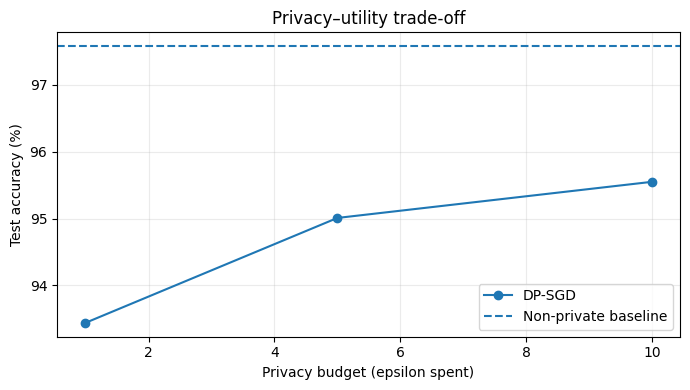

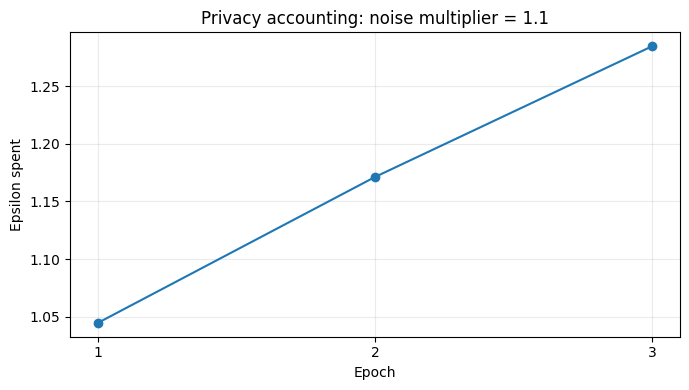

In [4]:
eps = [results[e][2][-1] for e in (1, 5, 10)]
accs = [results[e][1] for e in (1, 5, 10)]
plt.figure(figsize=(7, 4))
plt.plot(eps, accs, 'o-', label='DP-SGD')
plt.axhline(base_acc, linestyle='--', label='Non-private baseline')
plt.xlabel('Privacy budget (epsilon spent)'); plt.ylabel('Test accuracy (%)')
plt.title('Privacy–utility trade-off'); plt.grid(alpha=.25); plt.legend()
plt.tight_layout(); plt.savefig(OUT/'accuracy_vs_epsilon.png', dpi=180); plt.show()
plt.figure(figsize=(7, 4))
plt.plot(range(1, 4), history, 'o-')
plt.xticks([1, 2, 3]); plt.xlabel('Epoch'); plt.ylabel('Epsilon spent')
plt.title('Privacy accounting: noise multiplier = 1.1'); plt.grid(alpha=.25)
plt.tight_layout(); plt.savefig(OUT/'epsilon_vs_epoch.png', dpi=180); plt.show()


## Technical questions and recommendation

In [5]:
print(f'Q1: Baseline {base_acc:.2f}%; ' + ', '.join(f'epsilon={e}: {results[e][1]:.2f}%' for e in (10,5,1)))
print('Clipping bounds each example gradient; Gaussian noise reduces signal quality, which can reduce accuracy.')
print('Q2: Epsilon per epoch:', [round(x, 4) for x in history])
print('Privacy loss composes across updates. Delta is the additive slack in the DP probability inequality, not a literal probability of a breach.')
print('Q3: Confidence gaps:', {k: round(v[2], 4) for k,v in gaps.items()})
print('A larger positive gap may suggest overfitting; mean confidence alone cannot establish attack success or absence of leakage.')
# Illustrative acceptance rule, not a postal service requirement.
acceptable = [e for e in (1,5,10) if base_acc-results[e][1] <= 3.5]
recommendation = min(acceptable) if acceptable else None
print('Q4:', f'Recommend epsilon={recommendation} under a provisional 3.5 percentage-point accuracy-loss tolerance.' if recommendation else 'No tested budget meets the provisional 3.5-point tolerance; validate alternatives before deployment.')
print('DP trades utility for privacy and protects individual records, not automatically all samples from one citizen.')


Q1: Baseline 97.58%; epsilon=10: 95.55%, epsilon=5: 95.01%, epsilon=1: 93.44%
Clipping bounds each example gradient; Gaussian noise reduces signal quality, which can reduce accuracy.
Q2: Epsilon per epoch: [1.0447, 1.1713, 1.2847]
Privacy loss composes across updates. Delta is the additive slack in the DP probability inequality, not a literal probability of a breach.
Q3: Confidence gaps: {'Baseline': 0.001, 'DP (eps=1)': -0.0034}
A larger positive gap may suggest overfitting; mean confidence alone cannot establish attack success or absence of leakage.
Q4: Recommend epsilon=5 under a provisional 3.5 percentage-point accuracy-loss tolerance.
DP trades utility for privacy and protects individual records, not automatically all samples from one citizen.


In [6]:
lines = [f'Baseline: {base_acc:.2f}%']
for e, (_, a, h) in results.items():
    lines.append(f'Target {e}: accuracy {a:.2f}%, epsilon spent {h[-1]:.4f}')
lines += [f'Fixed noise accuracy: {fixed_acc:.2f}%', f'Accuracy cost: {cost:.2f} percentage points']
lines += [f'Epoch {i}: {v:.4f}' for i,v in enumerate(history,1)]
lines += [f'{k}: train={v[0]:.4f}, test={v[1]:.4f}, gap={v[2]:.4f}' for k,v in gaps.items()]
lines.append(f'Recommended target: {recommendation}')
(OUT/'observed_results.txt').write_text('\n'.join(lines))
print('Results and plots saved to', OUT.resolve())

Results and plots saved to /content/pin_code_dp_results
